In [74]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import PercentFormatter
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image

from safetensors.torch import load_file
from transformers import AutoConfig, AutoModelForImageClassification

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

In [75]:
label_to_id = pd.read_csv("Data/label_to_id_mapping.csv").set_index("label")["id"].to_dict()
dx=pd.read_csv("Data/Test_set.csv")

bboxes_frame = pd.read_csv("Data/collected_data.csv")
df=dx.copy()
label_mapping=pd.read_csv("Data/label_to_id_mapping.csv")

X=dx["X"].tolist()


dx["ID"]=dx["X"].str.split("/").str[-1]
dx["ID"]=dx["ID"].str.split(".").str[0]



In [76]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])


In [77]:

model_dir = Path("best_model")


config = AutoConfig.from_pretrained(model_dir,local_files_only=True,)

classes = label_mapping["label"].tolist()



config.id2label = {i: label for i, label in enumerate(classes)}
config.label2id = {label: i for i, label in enumerate(classes)}


model = AutoModelForImageClassification.from_config(config)

old_state_dict = load_file(model_dir / "model.safetensors",device="cpu")


def convert_vit_key(key):
    key = key.replace(
        "vit.encoder.layer.",
        "vit.layers.",
        1,
    )
    replacements = {
        ".attention.attention.query.": ".attention.q_proj.",
        ".attention.attention.key.": ".attention.k_proj.",
        ".attention.attention.value.": ".attention.v_proj.",
        ".attention.output.dense.": ".attention.o_proj.",
        ".intermediate.dense.": ".mlp.fc1.",
        ".output.dense.": ".mlp.fc2.",
    }

    for old, new in replacements.items():
        key = key.replace(old, new)

    return key


new_state_dict = {
    convert_vit_key(key): tensor
    for key, tensor in old_state_dict.items()
}



load_result = model.load_state_dict(new_state_dict,strict=True,)


In [78]:
cam_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])



annotations_by_id = bboxes_frame.set_index("id")
prepared_inputs, image_id, bbox = [], [], []

for image_idx in range(len(df)):
    image_path = df["X"].iloc[image_idx]
    code = Path(image_path).stem

    annotation = annotations_by_id.loc[code]
    boxes = ast.literal_eval(annotation["bboxes"])
    labels = ast.literal_eval(annotation["labels"])

    leading_boxes = [box for box, label in zip(boxes, labels) if label != "no_gesture"]

    with Image.open(image_path) as image:
        input_tensor = cam_transform(image.convert("RGB")).unsqueeze(0)

    prepared_inputs.append(input_tensor)
    image_id.append(code)
    bbox.append(leading_boxes)

In [79]:

class ViTLogitsWrapper(nn.Module):
    def __init__(self, vit_model):
        super().__init__()
        self.vit_model = vit_model

    def forward(self, pixel_values):
        return self.vit_model(
            pixel_values=pixel_values
        ).logits


device = next(model.parameters()).device
model.eval()

cam_model = ViTLogitsWrapper(model)
cam_model.to(device)
cam_model.eval()

ViTLogitsWrapper(
  (vit_model): ViTForImageClassification(
    (vit): ViTModel(
      (embeddings): ViTEmbeddings(
        (patch_embeddings): ViTPatchEmbeddings(
          (projection): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (layers): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (q_proj): Linear(in_features=192, out_features=192, bias=True)
            (k_proj): Linear(in_features=192, out_features=192, bias=True)
            (v_proj): Linear(in_features=192, out_features=192, bias=True)
            (o_proj): Linear(in_features=192, out_features=192, bias=True)
          )
          (layernorm_before): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
          (layernorm_after): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
          (mlp): ViTMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=192, ou

In [80]:

def reshape_transform(tensor):
    B, N, C = tensor.shape
    if N == 197:
        tensor = tensor[:, 1:, :]
    elif N == 198:
        tensor = tensor[:, 2:, :]
    else:
        raise ValueError(f"Unerwartete Token-Anzahl: {N}")
    tensor = tensor.reshape(B, 14, 14, C)
    return tensor.permute(0, 3, 1, 2).contiguous()



if hasattr(model, "deit"):
    backbone = model.deit
else:
    backbone = model.vit

if hasattr(backbone, "layers"):
    layers = backbone.layers
else:
    layers = backbone.encoder.layer


In [81]:
def model_prediction(input_tensor):
    with torch.no_grad():
        logits = cam_model(input_tensor)
        probabilities = torch.softmax(logits,dim=1)

    predicted_class = int(
        probabilities.argmax(dim=1).item()
    )

    confidence = float(
        probabilities[0, predicted_class].item()
    )

    class_name = model.config.id2label.get(
        predicted_class,
        str(predicted_class),
    )
    return class_name, predicted_class, confidence


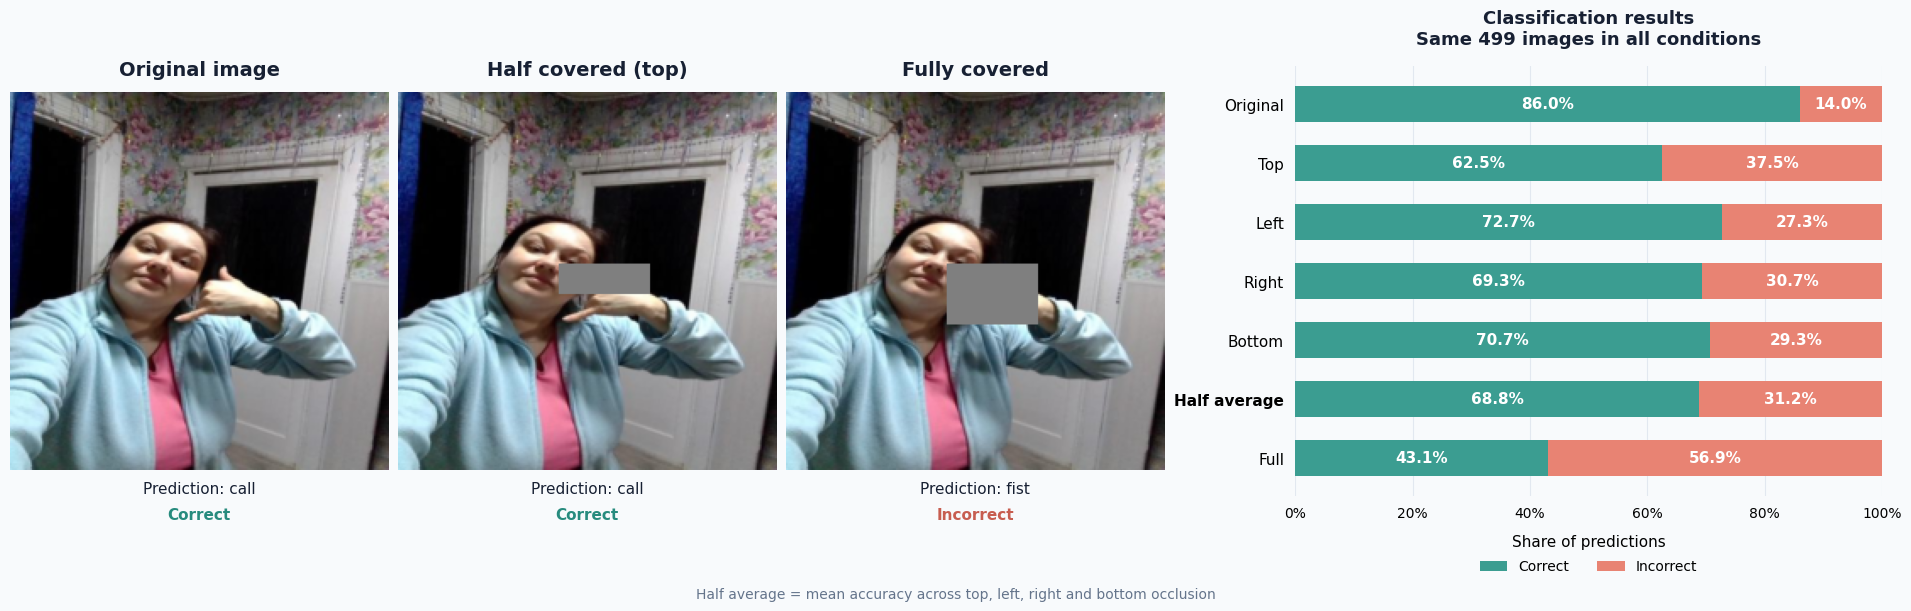

Tested: 499 | Skipped: 1


,Correct (%),Incorrect (%),Images tested,Predictions evaluated
Original,85.97,14.03,499,499
Top,62.53,37.47,499,499
Left,72.75,27.25,499,499
Right,69.34,30.66,499,499
Bottom,70.74,29.26,499,499
Half average,68.84,31.16,499,1996
Full,43.09,56.91,499,499


In [82]:
from matplotlib.ticker import PercentFormatter


@torch.inference_mode()
def compare_bbox_occlusion(cam_model, prepared_inputs, bbox, true_labels, device, show_image=5, half_example="Top"):
    true_labels = list(true_labels)

    if not (len(prepared_inputs) == len(bbox) == len(true_labels)):
        raise ValueError("Images, boxes and true labels must have the same length and order.")

    half_example = half_example.capitalize()
    if half_example not in ["Top", "Left", "Right", "Bottom"]:
        raise ValueError("half_example must be 'Top', 'Left', 'Right' or 'Bottom'.")

    cam_model.eval()
    conditions = ["Original", "Top", "Left", "Right", "Bottom", "Full"]
    results, example = [], None

    base_model = getattr(cam_model, "vit_model", cam_model)
    label_names = getattr(getattr(base_model, "config", None), "id2label", {})

    for i, prepared_input in enumerate(prepared_inputs):
        if not bbox[i]:
            continue

        image = prepared_input.to(device)
        if image.ndim == 3:
            image = image.unsqueeze(0)

        if image.ndim != 4 or image.shape[0] != 1:
            raise ValueError("Each input must contain exactly one image.")

        variants = {name: image.clone() for name in conditions}
        height, width = image.shape[-2:]
        covered = False

        for box in bbox[i]:
            x, y, w, h = map(float, box)
            x1, y1 = int(np.clip(np.floor(x * width), 0, width)), int(np.clip(np.floor(y * height), 0, height))
            x2, y2 = int(np.clip(np.ceil((x + w) * width), 0, width)), int(np.clip(np.ceil((y + h) * height), 0, height))

            if x2 <= x1 or y2 <= y1:
                continue

            mid_x, mid_y = (x1 + x2) // 2, (y1 + y2) // 2

            regions = {
                "Top": (x1, y1, x2, mid_y),
                "Bottom": (x1, mid_y, x2, y2),
                "Left": (x1, y1, mid_x, y2),
                "Right": (mid_x, y1, x2, y2),
                "Full": (x1, y1, x2, y2),
            }

            # Gray replacement with Normalize(mean=0.5, std=0.5)
            for name, (left, top, right, bottom) in regions.items():
                variants[name][:, :, top:bottom, left:right] = 0.0

            covered = True

        if not covered:
            continue

        # Evaluate every condition against the same ground-truth label
        predictions = cam_model(torch.cat([variants[name] for name in conditions], dim=0)).argmax(dim=1).tolist()
        true_class = int(true_labels[i])
        results.append([prediction == true_class for prediction in predictions])

        # Fall back to the first valid image if the requested example is unavailable
        if example is None or i == show_image:
            example = (i, [variants[name][0].cpu() for name in conditions], true_class, predictions)

    if not results:
        raise ValueError("No images with usable bounding boxes were found.")

    # Average over all four half-occlusion conditions
    rates = np.asarray(results, dtype=float).mean(axis=0) * 100
    half_average = rates[1:5].mean()

    correct_rates = np.concatenate([rates[:5], [half_average], rates[5:]])
    incorrect_rates = 100 - correct_rates
    categories = ["Original", "Top", "Left", "Right", "Bottom", "Half average", "Full"]
    tested, skipped = len(results), len(prepared_inputs) - len(results)

    summary = pd.DataFrame({
        "Correct (%)": correct_rates,
        "Incorrect (%)": incorrect_rates,
        "Images tested": tested,
        "Predictions evaluated": [tested] * 5 + [4 * tested, tested],
    }, index=categories)

    # Display original, one half-covered example and full coverage
    i, tensors, true_class, predictions = example
    true_name = label_names.get(true_class, str(true_class))
    selected_indices = [0, conditions.index(half_example), conditions.index("Full")]
    titles = ["Original image", f"Half covered ({half_example.lower()})", "Fully covered"]

    fig, axes = plt.subplots(1, 4, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1, 1, 1.55]}, constrained_layout=True)
    fig.patch.set_facecolor("#F8FAFC")

    for ax, index, title in zip(axes[:3], selected_indices, titles):
        tensor = tensors[index]
        prediction = predictions[index]
        predicted_name = label_names.get(prediction, str(prediction))
        correct = prediction == true_class

        display_image = (tensor.float() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

        ax.imshow(display_image)
        ax.set_title(title, fontsize=14, fontweight="bold", color="#172033", pad=12)
        ax.text(0.5, -0.06, f"Prediction: {predicted_name}", transform=ax.transAxes, ha="center", fontsize=11, color="#172033")
        ax.text(0.5, -0.13, "Correct" if correct else "Incorrect", transform=ax.transAxes, ha="center", fontsize=11, fontweight="bold", color="#278B7E" if correct else "#C75D50")
        ax.axis("off")

    # Show all classification rates
    ax = axes[3]
    ax.set_facecolor("#F8FAFC")
    y_positions = np.arange(len(categories))

    correct_bars = ax.barh(y_positions, correct_rates, height=0.62, color="#3B9D91", label="Correct", zorder=3)
    incorrect_bars = ax.barh(y_positions, incorrect_rates, left=correct_rates, height=0.62, color="#E88373", label="Incorrect", zorder=3)

    for bars in [correct_bars, incorrect_bars]:
        labels = [f"{bar.get_width():.1f}%" if bar.get_width() >= 6 else "" for bar in bars]
        ax.bar_label(bars, labels=labels, label_type="center", color="white", fontsize=11, fontweight="bold")

    ax.set_yticks(y_positions)
    ax.set_yticklabels(categories, fontsize=11)
    ax.get_yticklabels()[5].set_fontweight("bold")
    ax.invert_yaxis()

    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_xlabel("Share of predictions", fontsize=11, labelpad=10)
    ax.set_title(f"Classification results\nSame {tested:,} images in all conditions", fontsize=13, fontweight="bold", color="#172033", pad=16)
    ax.grid(axis="x", color="#E2E8F0", zorder=0)
    ax.tick_params(axis="both", length=0, pad=8)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.supxlabel("Half average = mean accuracy across top, left, right and bottom occlusion", fontsize=10, color="#64748B")

    plt.show()
    plt.close(fig)

    print(f"Tested: {tested} | Skipped: {skipped}")
    return summary.round(2)


true_labels = df["y"].iloc[:len(prepared_inputs)].tolist()
occlusion_summary = compare_bbox_occlusion(cam_model, prepared_inputs, bbox, true_labels, device, show_image=5, half_example="Top")
occlusion_summary